# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv('power_grid.csv')

In [3]:
df

,timestamp,district_id,electricity_demand_mwh,grid_capacity_mwh,solar_generation_mwh,wind_generation_mwh,total_renewable_generation_mwh,renewable_generation_percent,grid_load_percent,grid_stress_index,outage_flag,outage_duration_minutes,sensor_status
0,2023-01-01 00:00:00,D01,249.143374,617.454012,0.0,0.000000,0.000000,0.000000,40.350110,0.350110,0,0.0,Normal
1,2023-01-01 00:00:00,D02,306.555550,843.839288,0.0,0.000000,0.000000,0.000000,36.328665,0.000000,0,0.0,Normal
2,2023-01-01 00:00:00,D03,451.257617,1306.398788,0.0,0.000000,0.000000,0.000000,34.542103,0.000000,0,0.0,Normal
3,2023-01-01 00:00:00,D04,171.874027,399.916155,0.0,0.000000,0.000000,0.000000,42.977515,2.977515,0,0.0,Normal
4,2023-01-01 00:00:00,D05,160.629531,342.471072,0.0,0.000000,0.000000,0.000000,46.903095,6.903095,0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
526075,2025-12-31 23:00:00,D16,195.659593,299.170225,0.0,0.000000,0.000000,0.000000,65.400757,25.400757,0,0.0,Normal
526076,2025-12-31 23:00:00,D17,334.867970,579.903013,0.0,0.000000,0.000000,0.000000,57.745513,17.745513,0,0.0,Normal
526077,2025-12-31 23:00:00,D18,170.702369,284.614039,0.0,3.582555,3.582555,2.086491,59.976792,19.976792,0,0.0,Normal
526078,2025-12-31 23:00:00,D19,171.154912,249.277801,0.0,3.041694,3.041694,1.766835,68.660311,28.660311,0,0.0,Normal


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 526080 entries, 0 to 526079
Data columns (total 13 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   timestamp                       526080 non-null  str    
 1   district_id                     526080 non-null  str    
 2   electricity_demand_mwh          520604 non-null  float64
 3   grid_capacity_mwh               520604 non-null  float64
 4   solar_generation_mwh            520604 non-null  float64
 5   wind_generation_mwh             520604 non-null  float64
 6   total_renewable_generation_mwh  520604 non-null  float64
 7   renewable_generation_percent    520604 non-null  float64
 8   grid_load_percent               520604 non-null  float64
 9   grid_stress_index               520604 non-null  float64
 10  outage_flag                     526080 non-null  int64  
 11  outage_duration_minutes         520604 non-null  float64
 12  sensor_status              

### Converting timestamps to datetime

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

### Checking for duplicated composite key (and dropping duplicates if existed)

In [6]:
# Checking for duplicated composite key
df[['timestamp', 'district_id']].duplicated().sum()

np.int64(0)

### Sorting data by districts then timestamps

In [7]:
df = df.sort_values(['district_id', 'timestamp']).reset_index(drop=True)

### Understanding columns + feature engineering (if needed)

In [8]:
df.describe()

,timestamp,electricity_demand_mwh,grid_capacity_mwh,solar_generation_mwh,wind_generation_mwh,total_renewable_generation_mwh,renewable_generation_percent,grid_load_percent,grid_stress_index,outage_flag,outage_duration_minutes
count,526080,520604.000000,520604.000000,520604.000000,520604.000000,520604.000000,520604.000000,520604.000000,520604.000000,526080.000000,520604.000000
mean,2024-07-01 23:30:00,310.462419,522.208472,37.588660,5.706406,43.295066,12.448638,61.591634,22.509907,0.000736,0.050664
min,2023-01-01 00:00:00,24.633552,82.905533,0.000000,0.000000,0.000000,0.000000,28.958578,0.000000,0.000000,0.000000
25%,2023-10-01 23:45:00,171.433814,289.333384,0.000000,0.000000,0.000000,0.000000,47.835687,8.115470,0.000000,0.000000
50%,2024-07-01 23:30:00,241.601721,399.916155,0.000000,0.000000,7.763824,3.605984,62.849630,23.003998,0.000000,0.000000
75%,2025-04-01 23:15:00,414.566035,749.944816,57.683419,3.840269,63.525117,25.328366,74.386589,34.612063,0.000000,0.000000
max,2025-12-31 23:00:00,1197.905003,1306.398788,391.785804,261.093908,556.687553,82.437858,197.071775,100.000000,1.000000,296.000000
std,NaN,201.774534,328.135745,63.633119,17.122530,66.783807,14.657437,17.407242,16.490248,0.027113,2.393122


In [9]:
df[df['electricity_demand_mwh'] > df['grid_capacity_mwh']]

,timestamp,district_id,electricity_demand_mwh,grid_capacity_mwh,solar_generation_mwh,wind_generation_mwh,total_renewable_generation_mwh,renewable_generation_percent,grid_load_percent,grid_stress_index,outage_flag,outage_duration_minutes,sensor_status
24645,2025-10-23 21:00:00,D01,623.628004,617.454012,0.000000,0.000000,0.000000,0.000000,100.999911,60.999911,0,0.0,Normal
25220,2025-11-16 20:00:00,D01,653.361750,617.454012,0.000000,0.000000,0.000000,0.000000,105.815451,65.815451,0,0.0,Normal
25221,2025-11-16 21:00:00,D01,627.624833,617.454012,0.000000,0.000000,0.000000,0.000000,101.647219,61.647219,0,0.0,Normal
83108,2023-06-24 20:00:00,D04,402.851215,399.916155,0.000000,0.191019,0.191019,0.047299,100.733919,65.733919,0,0.0,Normal
83109,2023-06-24 21:00:00,D04,419.440975,399.916155,0.000000,0.000000,0.000000,0.000000,104.882228,69.882228,0,0.0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
525208,2025-11-25 16:00:00,D20,294.929872,289.333384,70.996278,3.861015,74.857293,25.295619,101.934270,61.934270,0,0.0,Normal
525209,2025-11-25 17:00:00,D20,302.427120,289.333384,77.029417,10.037506,87.066923,28.694509,104.525484,64.525484,0,0.0,Normal
525210,2025-11-25 18:00:00,D20,292.742521,289.333384,0.000000,0.000000,0.000000,0.000000,101.178273,61.178273,0,0.0,Normal
525211,2025-11-25 19:00:00,D20,332.538847,289.333384,0.000000,9.811336,9.811336,2.941587,114.932761,74.932761,0,0.0,Normal


In [10]:
df[~np.isclose(df['solar_generation_mwh'] + df['wind_generation_mwh'], df['total_renewable_generation_mwh'], equal_nan=True)]

,timestamp,district_id,electricity_demand_mwh,grid_capacity_mwh,solar_generation_mwh,wind_generation_mwh,total_renewable_generation_mwh,renewable_generation_percent,grid_load_percent,grid_stress_index,outage_flag,outage_duration_minutes,sensor_status


In [11]:
df[(df['outage_duration_minutes'] > 0) & (df['outage_flag'] == 0)]

,timestamp,district_id,electricity_demand_mwh,grid_capacity_mwh,solar_generation_mwh,wind_generation_mwh,total_renewable_generation_mwh,renewable_generation_percent,grid_load_percent,grid_stress_index,outage_flag,outage_duration_minutes,sensor_status


In [12]:
df['sensor_status'].unique()

<ArrowStringArray>
['Normal', 'Communication-Loss', 'Outage-Affected']
Length: 3, dtype: str

In [13]:
df['sensor_status'].value_counts()

sensor_status
Normal                520604
Communication-Loss      5403
Outage-Affected           73
Name: count, dtype: int64

In [14]:
df['outage_flag'].value_counts()

outage_flag
0    525693
1       387
Name: count, dtype: int64

## Checking nulls

In [15]:
df.isnull().sum()

timestamp                            0
district_id                          0
electricity_demand_mwh            5476
grid_capacity_mwh                 5476
solar_generation_mwh              5476
wind_generation_mwh               5476
total_renewable_generation_mwh    5476
renewable_generation_percent      5476
grid_load_percent                 5476
grid_stress_index                 5476
outage_flag                          0
outage_duration_minutes           5476
sensor_status                        0
dtype: int64

In [16]:
# Check if the nulls is due to abnormal sensor state
sensor_cols = ['electricity_demand_mwh', 'grid_capacity_mwh', 'solar_generation_mwh',
               'wind_generation_mwh', 'total_renewable_generation_mwh', 'renewable_generation_percent',
               'grid_load_percent', 'grid_stress_index', 'outage_duration_minutes']
for col in sensor_cols:
    print(f"{col}: {((df[col].isnull()) & (df['sensor_status'] == 'Normal')).sum()}")
# Since all the results are 0 that means There wasn't any observation where it was null while the sensor is normally working

electricity_demand_mwh: 0
grid_capacity_mwh: 0
solar_generation_mwh: 0
wind_generation_mwh: 0
total_renewable_generation_mwh: 0
renewable_generation_percent: 0
grid_load_percent: 0
grid_stress_index: 0
outage_duration_minutes: 0


In [17]:
# Check how many missing value happened in every detection cause of (Communication-Loss)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Communication-Loss')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")

electricity_demand_mwh: 5403 which is 98.67% of total null detections
grid_capacity_mwh: 5403 which is 98.67% of total null detections
solar_generation_mwh: 5403 which is 98.67% of total null detections
wind_generation_mwh: 5403 which is 98.67% of total null detections
total_renewable_generation_mwh: 5403 which is 98.67% of total null detections
renewable_generation_percent: 5403 which is 98.67% of total null detections
grid_load_percent: 5403 which is 98.67% of total null detections
grid_stress_index: 5403 which is 98.67% of total null detections
outage_duration_minutes: 5403 which is 98.67% of total null detections


In [18]:
# Check how many missing value happened in every detection cause of (Outage-Affected)
for col in sensor_cols:
    observations = ((df[col].isnull()) & (df['sensor_status'] == 'Outage-Affected')).sum()
    print(f"{col}: {observations} which is {observations / df[col].isnull().sum() * 100:.2f}% of total null detections")

electricity_demand_mwh: 73 which is 1.33% of total null detections
grid_capacity_mwh: 73 which is 1.33% of total null detections
solar_generation_mwh: 73 which is 1.33% of total null detections
wind_generation_mwh: 73 which is 1.33% of total null detections
total_renewable_generation_mwh: 73 which is 1.33% of total null detections
renewable_generation_percent: 73 which is 1.33% of total null detections
grid_load_percent: 73 which is 1.33% of total null detections
grid_stress_index: 73 which is 1.33% of total null detections
outage_duration_minutes: 73 which is 1.33% of total null detections


## Checking outliers

In [19]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return df[(df[column] < lower) | (df[column] > upper)]

continuous_cols = ['electricity_demand_mwh', 'grid_capacity_mwh', 'solar_generation_mwh', 'wind_generation_mwh', 'total_renewable_generation_mwh',
    'renewable_generation_percent', 'grid_load_percent', 'grid_stress_index', 'outage_duration_minutes']

for col in continuous_cols:
     print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

electricity_demand_mwh: 21915, mean: 310.46, above upper = 21915, below lower = 0
grid_capacity_mwh: 0, mean: 522.21, above upper = 0, below lower = 0
solar_generation_mwh: 41659, mean: 37.59, above upper = 41659, below lower = 0
wind_generation_mwh: 73377, mean: 5.71, above upper = 73377, below lower = 0
total_renewable_generation_mwh: 37888, mean: 43.30, above upper = 37888, below lower = 0
renewable_generation_percent: 134, mean: 12.45, above upper = 134, below lower = 0
grid_load_percent: 540, mean: 61.59, above upper = 540, below lower = 0
grid_stress_index: 631, mean: 22.51, above upper = 631, below lower = 0
outage_duration_minutes: 310, mean: 0.05, above upper = 310, below lower = 0


## Validating Outliers

### electricity_demand_mwh

In [20]:
electricity_demand_outliers = find_outliers_iqr(df, 'electricity_demand_mwh')
demand_over_capacity = df[df['electricity_demand_mwh'] > df['grid_capacity_mwh']]

### Renewable generation

In [21]:
renewable_outliers = find_outliers_iqr(df, 'total_renewable_generation_mwh')

### grid_load_percent and grid_stress_index

In [22]:
overload = df[df['grid_load_percent'] > 100]

stress_outliers = find_outliers_iqr(df, 'grid_stress_index')

print(f'Grid load values above 100%: {len(overload)}')
print(f'Grid stress outliers: {len(stress_outliers)}')

Grid load values above 100%: 3144
Grid stress outliers: 631


### outage_duration_minutes

In [23]:
outage_duration_outliers = find_outliers_iqr(df, 'outage_duration_minutes')
duration_without_outage = df[(df['outage_flag'] == 0) & (df['outage_duration_minutes'] > 0)]
outage_without_duration = df[(df['outage_flag'] == 1) & (df['outage_duration_minutes'] <= 0)]

print(f'Outage duration outliers: {len(outage_duration_outliers)}')
print(f'Positive duration without outage flag: {len(duration_without_outage)}')
print(f'Outage flag without positive duration: {len(outage_without_duration)}')

Outage duration outliers: 310
Positive duration without outage flag: 0
Outage flag without positive duration: 0


# Important KPIs

## Electricity demand and grid load

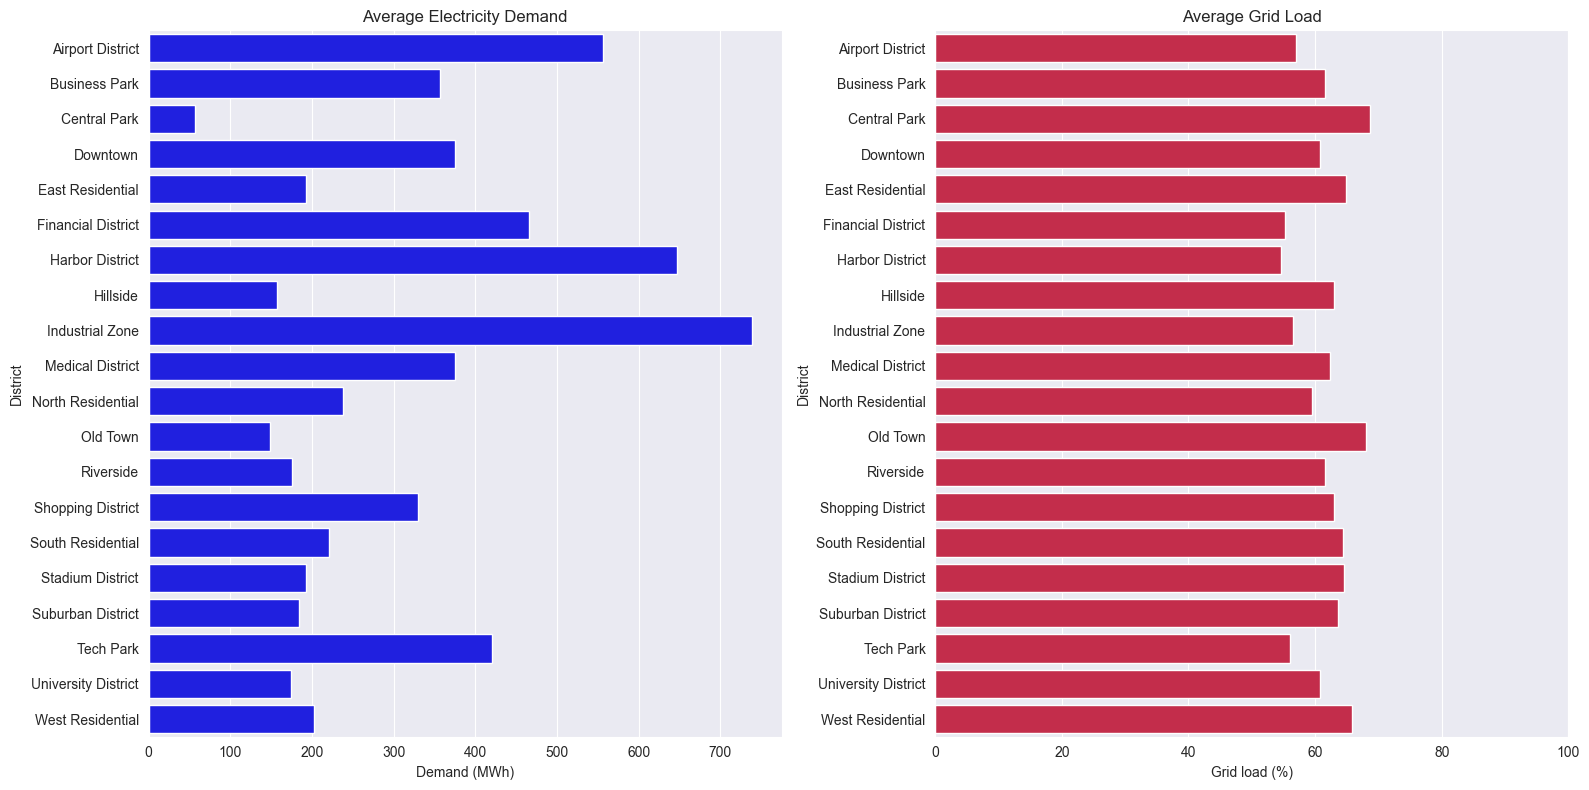

In [24]:
districts = pd.read_csv('districts.csv')
districts_power = districts.merge(df, on='district_id')

demand_load = districts_power.groupby('district_name').agg(
    average_demand=('electricity_demand_mwh', 'mean'),
    average_load=('grid_load_percent', 'mean')
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(demand_load, x='average_demand', y='district_name', color='blue', ax=ax[0])
ax[0].set_title('Average Electricity Demand')
ax[0].set_xlabel('Demand (MWh)')
ax[0].set_ylabel('District')

sns.barplot(demand_load, x='average_load', y='district_name', color='crimson', ax=ax[1])
ax[1].set_title('Average Grid Load')
ax[1].set_xlabel('Grid load (%)')
ax[1].set_ylabel('District')
ax[1].set_xlim(0, 100)


plt.tight_layout()
plt.show()

## Renewable-energy percentage

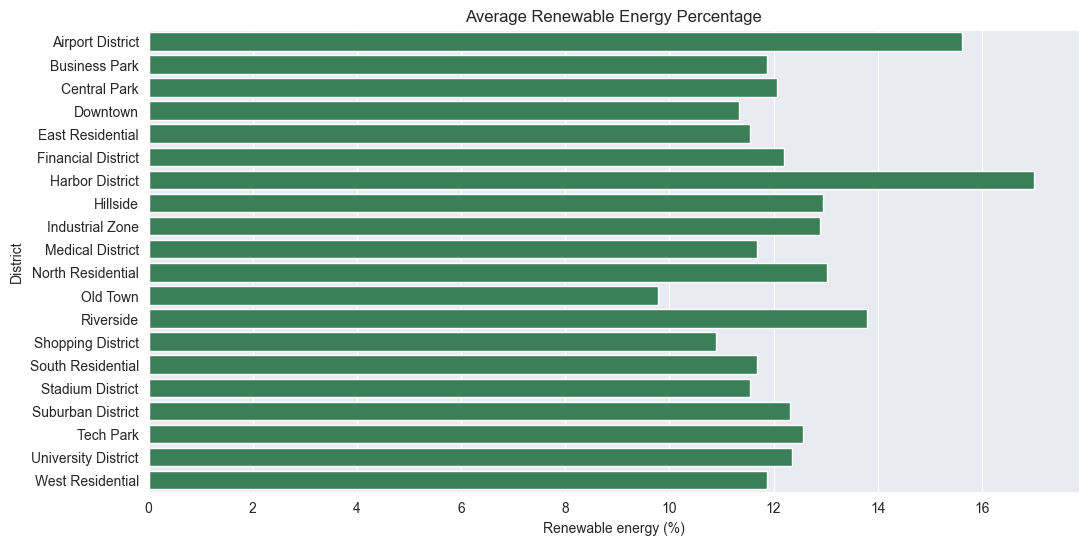

In [25]:
renewable_percent = districts_power.groupby('district_name').agg(
    average_renewable_percent=('renewable_generation_percent', 'mean')
).reset_index()

sns.barplot(renewable_percent, x='average_renewable_percent', y='district_name', color='seagreen')
plt.title('Average Renewable Energy Percentage')
plt.xlabel('Renewable energy (%)')
plt.ylabel('District')
plt.show()

## Grid-stress rate

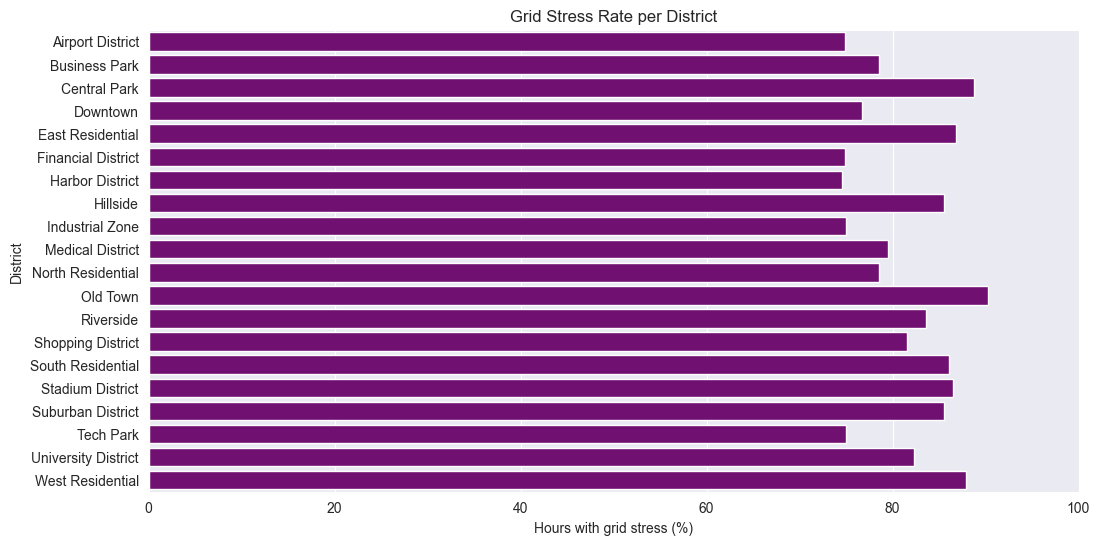

In [26]:
stress_rate = districts_power.groupby('district_name').agg(
    grid_stress_rate=('grid_stress_index', lambda x: (x > 0).mean() * 100)
).reset_index()

sns.barplot(stress_rate, x='grid_stress_rate', y='district_name', color='purple')
plt.title('Grid Stress Rate per District')
plt.xlabel('Hours with grid stress (%)')
plt.ylabel('District')
plt.xlim(0, 100)
plt.show()

## Outage frequency and outage duration

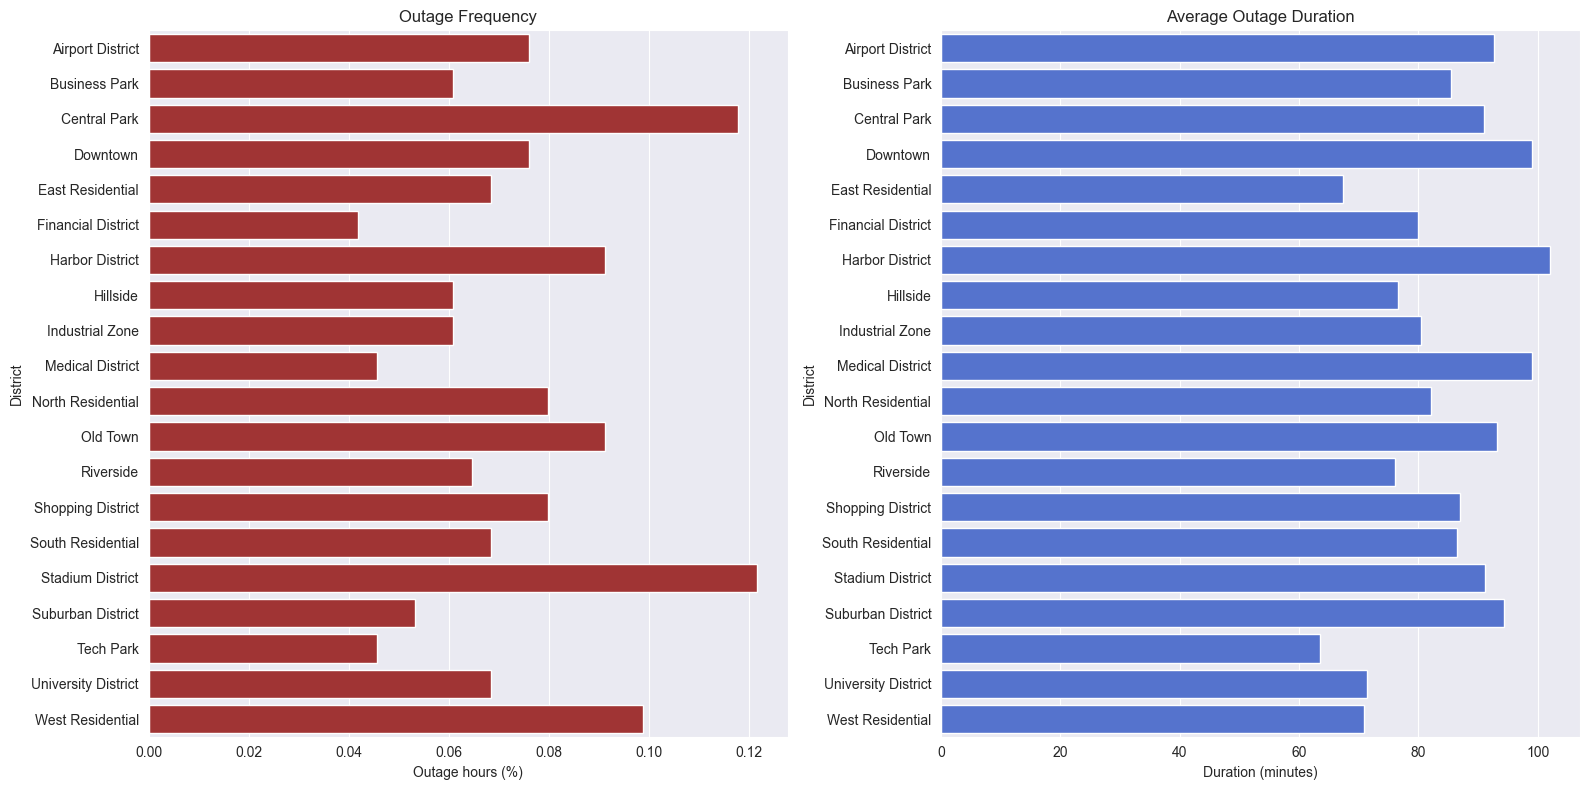

In [27]:
outage = districts_power.groupby('district_name').agg(
    outage_rate=('outage_flag', lambda x: x.mean() * 100),
    average_outage_duration=('outage_duration_minutes', lambda x: x[x > 0].mean())
).reset_index()

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(outage, x='outage_rate', y='district_name', color='firebrick', ax=ax[0])
ax[0].set_title('Outage Frequency')
ax[0].set_xlabel('Outage hours (%)')
ax[0].set_ylabel('District')

sns.barplot(outage, x='average_outage_duration', y='district_name', color='royalblue', ax=ax[1])
ax[1].set_title('Average Outage Duration')
ax[1].set_xlabel('Duration (minutes)')
ax[1].set_ylabel('District')

plt.tight_layout()
plt.show()

# Data Cleaning

## Handling Nulls

In [ ]:
df = df.sort_values(['district_id', 'timestamp'])
cleaned_power = df.ffill().bfill()
cleaned_power.to_csv('data/cleaned_power_grid.csv', index=False)